# Q1–Q4: Tìm hiểu tiểu hành tinh theo tiêu chí D1–D4

Bộ câu hỏi được điều chỉnh theo yêu cầu: **cả bộ bao phủ D1–D4 và mỗi câu
dùng ít nhất hai tiêu chí trong D1–D4**. Câu hỏi là đề xuất chờ nhóm duyệt;
chưa phân công chính thức Q5–Q6. Phần trình bày dùng tiếng Việt.

- **D1 — Combining data:** ghép bảng phân loại phổ từ JPL với dataset Kaggle,
  bổ sung nhãn chưa có trong dataset, kiểm tra khóa và số bản ghi trước/sau.
- **D2 — Reshaping & time:** dùng `melt` và `pivot` để chuyển bảng độ bao phủ
  nhiều loại số đo giữa dạng rộng/dài, phục vụ đối chiếu và biểu đồ. Chỉ dùng
  phần **reshaping**; không tạo phân tích thời gian từ `epoch`.
- **D3 — Derived variables:** tạo các cờ có số đo, đủ bộ thông tin, albedo thấp,
  mức lệch đường kính và khoảng kích thước/H có ý nghĩa rõ ràng.
- **D4 — Controlling for a confounder:** so sánh trong cùng khoảng H hoặc
  đường kính; phân biệt thay đổi cơ cấu nhóm với khác biệt tổng thể.

D5/D6 không phải tiêu chí của bộ câu hỏi này. Notebook không dùng kiểm định,
bootstrap hoặc khoảng tin cậy làm nội dung phân tích chính.

| ID | Câu hỏi cụ thể | Tiêu chí |
|---|---|---|
| Q1 | Sau khi ghép phân loại phổ SMASSII từ JPL vào dataset, nhóm phổ C và S có tỷ lệ albedo dưới 0,10 chênh lệch bao nhiêu điểm phần trăm khi so sánh cùng khoảng đường kính? | D1, D3, D4 |
| Q2 | Trong từng khoảng độ sáng tuyệt đối H, nhóm NEO và không-NEO có tỷ lệ được ghi nhận đường kính, albedo và độ bất định đường kính khác nhau thế nào? Nhóm nào có tỷ lệ đủ cả H–đường kính–albedo cao hơn? | D2, D3, D4 |
| Q3 | Với các đối tượng có đủ H, albedo và đường kính, nếu tính đường kính từ H với albedo cố định 0,15, kết quả thường cao hay thấp hơn đường kính ghi nhận bao nhiêu phần trăm, và khác nhau thế nào giữa các nhóm albedo? | D3, D4 |
| Q4 | So với MBA, OMB và TJN có tỷ lệ đối tượng có albedo dưới 0,10 chênh lệch bao nhiêu điểm phần trăm khi so sánh cùng khoảng đường kính? | D3, D4 |

## A. Dữ liệu, thuật ngữ và cách đọc notebook

**NEO** là đối tượng gần Trái Đất theo nhãn nguồn, không có nghĩa sắp va chạm.
**H** là cấp sao tuyệt đối: số nhỏ hơn tương ứng sáng hơn trong điều kiện quy
ước, không phải đường kính. **Albedo** là suất phản chiếu hình học; ngưỡng 0,10
chỉ là quy ước tóm tắt trong bài này, không phải ranh giới vật lý tuyệt đối.

**Lớp quỹ đạo** (`class`: MBA, OMB, TJN...) mô tả quỹ đạo. **Lớp phổ**
(`spec_B`: C, S, Ch...) mô tả đặc điểm phổ theo hệ SMASSII. Đây là hai loại
phân loại khác nhau; không suy loại phổ từ mã lớp quỹ đạo.

Mỗi câu được trình bày theo thứ tự: **hỏi gì → vì sao hỏi → dữ liệu nào →
quy trình → giải thích code → biểu đồ → kết quả và giới hạn**. Các kết luận
chỉ áp dụng cho tập bản ghi đủ điều kiện trong từng phép so sánh, không mặc
định đại diện cho mọi tiểu hành tinh. Không khẳng định quan hệ nhân quả.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from datetime import datetime, timezone
from urllib.parse import urlencode
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Nạp lại mã trên đĩa khi chạy lại ô này trong một kernel đang mở.
import importlib
import src.nonml_analysis as nonml_analysis
importlib.reload(nonml_analysis)
from src.nonml_analysis import load_taxonomy, merge_taxonomy, standardized_rates

DATA_PATH = PROJECT_ROOT / "data/processed/asteroids_clean.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Cần chạy Notebook 01 trước.")
USE_COLUMNS = ["id", "spkid", "pdes", "class", "neo", "H", "diameter", "albedo", "diameter_sigma"]
df = pd.read_csv(DATA_PATH, usecols=USE_COLUMNS,
    dtype={c: "string" for c in ["id", "spkid", "pdes", "class", "neo"]},
    keep_default_na=False, na_values=[""], low_memory=False, float_precision="round_trip")
assert df.id.notna().all() and df.id.is_unique
input_rows = len(df)


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()


source_sha256 = sha256(DATA_PATH)
audit = []


def subset(table, mask, question, reason):
    result = table.loc[mask.fillna(False)].copy()
    audit.append({"Câu hỏi": question, "Bước": reason, "Trước": len(table),
                  "Sau": len(result), "Không dùng trong phân tích này": len(table)-len(result)})
    print(f"{question} | {reason}: {len(table):,} → {len(result):,} dòng; "
          f"không dùng {len(table)-len(result):,} dòng.")
    return result


LABELS = {"n_reference": "n nhóm tham chiếu", "n_target": "n nhóm đích",
          "rate_reference": "Tỷ lệ nhóm tham chiếu", "rate_target": "Tỷ lệ nhóm đích",
          "weight": "Trọng số"}
H_EDGES = [-np.inf, 10, 12, 14, 16, 18, 20, 22, 24, np.inf]
D_EDGES = [0, 2, 5, 10, 20, 50, np.inf]
GROUP_LABELS = {"N": "Không-NEO", "Y": "NEO"}
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})
print(f"Nguồn Kaggle đã làm sạch: {len(df):,} dòng, đọc {len(df.columns)} cột cần dùng.")
print("SHA-256:", source_sha256)
display(df.head())

Nguồn Kaggle đã làm sạch: 958,524 dòng, đọc 9 cột cần dùng.
SHA-256: 4be917aad7217fa69215d529f1ed4e3c0cc9f67bc1bc898af2113f5d30a37ad5


,id,spkid,pdes,neo,H,diameter,albedo,diameter_sigma,class
0,a0000001,2000001,1,N,3.40,939.400,0.0900,0.200,MBA
1,a0000002,2000002,2,N,4.20,545.000,0.1010,18.000,MBA
2,a0000003,2000003,3,N,5.33,246.596,0.2140,10.594,MBA
3,a0000004,2000004,4,N,3.00,525.400,0.4228,0.200,MBA
4,a0000005,2000005,5,N,6.90,106.699,0.2740,3.140,MBA


### Vì sao dùng các lệnh này?

- `usecols` chỉ đọc cột cần thiết, giảm bộ nhớ; cột ID đọc dạng chuỗi để không
  mất chữ số 0 hoặc hiểu ID như số đo.
- `np.isfinite` loại giá trị thiếu/vô hạn khỏi **phép tính cần số đo đó**.
  Không xóa missing toàn bộ vì từng câu cần tập thông tin khác nhau.
- `.copy()` tạo dữ liệu riêng cho từng câu. Hàm `subset` ghi số dòng trước/sau
  để người đọc thấy chính xác tập đang được phân tích.
- `groupby` tính trong từng nhóm; với cờ 0/1, `mean` là tỷ lệ, `sum` là số
  trường hợp có cờ 1. Mẫu số của tỷ lệ có số đo phải gồm cả bản ghi thiếu số đo.

### “Cùng cơ cấu tầng” được tính thế nào? (D4)

Trong mỗi khoảng kích thước/H, tính tỷ lệ riêng của hai nhóm. Chỉ giữ khoảng
có ít nhất 30 bản ghi mỗi nhóm; đây là ngưỡng thực hành để tránh ô quá ít mẫu,
không phải bảo đảm về suy luận thống kê. Trọng số của tầng s bằng số dòng gộp
hai nhóm trong tầng chia cho tổng số dòng của các tầng chung.

Tỷ lệ chuẩn hóa của mỗi nhóm = tổng `trọng số tầng × tỷ lệ trong tầng`.
Hai nhóm dùng **cùng trọng số**, nhờ đó giảm ảnh hưởng của cơ cấu tầng khác nhau.
Hàm `standardized_rates` trả cả số mẫu, tỷ lệ thô trong vùng chung và tỷ lệ
chuẩn hóa. Bảng toàn tập → vùng chung → chuẩn hóa giúp tách **đổi đối tượng**
khỏi **đổi cơ cấu trọng số**. Phân tầng vẫn có thể còn nhiễu trong từng khoảng;
không được diễn giải như đã kiểm soát mọi yếu tố hoặc chứng minh nguyên nhân.

# Q1. Ghép loại phổ để so sánh albedo của nhóm C và S

**Câu hỏi cụ thể:** Sau khi ghép phân loại phổ SMASSII từ JPL vào dataset, nhóm phổ C và S có tỷ lệ albedo dưới 0,10 chênh lệch bao nhiêu điểm phần trăm khi so sánh cùng khoảng đường kính?

**Tiêu chí: D1 + D3 + D4.** D1 bổ sung nhãn phổ SMASSII chưa có trong dataset;
D3 tạo nhóm phổ C/S, cờ albedo thấp và khoảng đường kính; D4 kiểm soát cơ cấu kích thước.

## Q1.1. Vì sao đáng hỏi?

Dataset có albedo nhưng chưa có nhãn phổ để biết các nhóm bề mặt theo phổ có
khác mức phản chiếu hay không. Ghép thêm `spec_B` cho phép kiểm tra liên hệ này.
Theo mô tả nghiên cứu về hệ Bus/SMASSII, albedo không được dùng để xác định
phân loại phổ này; điều đó giúp tránh việc tự gán nhóm C/S từ chính albedo rồi
“phát hiện” chúng khác nhau. Đây vẫn là liên hệ quan sát, không phải nhận diện
thành phần hóa học chính xác hoặc kiểm định một quy luật mới.

## Q1.2. Nguồn bổ sung và giới hạn thời điểm

Dùng [JPL SBDB Query API](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html),
lấy ba trường `spkid`, `pdes`, `spec_B` cho đối tượng có `spec_B`.
Bản JSON và thông tin ngày tải/URL/SHA-256 được lưu ở `data/raw/` để lần chạy
sau đọc lại cùng bản chụp. Chỉ lần đầu thiếu file mới cần mạng.

**Bảng JPL là nhãn phổ tại lúc tải, không phải nhãn đã xác nhận tồn tại đúng
thời điểm bản Kaggle được xuất.** Chỉ bổ sung nhãn phổ; không thay các số đo
vật lý/quỹ đạo cũ bằng giá trị hiện tại. Lần chạy sau với bản chụp mới có thể khác.

In [2]:
TAXONOMY_PATH = PROJECT_ROOT / "data/raw/jpl_smassii_taxonomy.json"
METADATA_PATH = PROJECT_ROOT / "data/raw/jpl_smassii_taxonomy_metadata.json"
params = {"fields": "spkid,pdes,spec_B", "sb-cdata": json.dumps({"AND": ["spec_B|DF"]}, separators=(",", ":"))}
taxonomy_url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api?" + urlencode(params)
if not TAXONOMY_PATH.exists():
    with urlopen(taxonomy_url, timeout=60) as response:
        content = response.read()
    payload = json.loads(content)
    if payload.get("fields") != ["spkid", "pdes", "spec_B"] or not payload.get("data"):
        raise ValueError("Phản hồi JPL không đúng bảng phân loại dự kiến.")
    TAXONOMY_PATH.parent.mkdir(parents=True, exist_ok=True)
    TAXONOMY_PATH.write_bytes(content)
    metadata = {"retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                "url": taxonomy_url, "sha256": sha256(TAXONOMY_PATH),
                "api_signature": payload.get("signature"), "count": payload.get("count")}
    METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
if not METADATA_PATH.is_file():
    raise FileNotFoundError("Thiếu metadata của bản chụp JPL; cần kiểm tra nguồn file trước khi chạy.")
taxonomy_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
assert taxonomy_metadata["sha256"] == sha256(TAXONOMY_PATH)
taxonomy = load_taxonomy(TAXONOMY_PATH)
display(pd.Series(taxonomy_metadata).to_frame("Thông tin bản chụp JPL"))
display(taxonomy.head())
print("Số khóa spkid trùng giữa hai nguồn:", df.spkid.isin(taxonomy.jpl_spkid).sum())
joined, join_audit, unmatched_taxonomy = merge_taxonomy(df, taxonomy)
display(join_audit)
print("Các đối tượng JPL chưa ghép được với bản Kaggle:")
display(unmatched_taxonomy)

,Thông tin bản chụp JPL
retrieved_at_utc,2026-11-16T01:18:06.403945+00:00
url,https://ssd-api.jpl.nasa.gov/sbdb_query.api?fi...
sha256,1ea46e00177e1aebc194a210f460ba0a8c6201af5a3832...
api_signature,"{'version': '1.0', 'source': 'NASA/JPL SBDB (S..."
count,1666


,jpl_spkid,pdes,spec_B
0,20000001,1,C
1,20000002,2,B
2,20000003,3,Sk
3,20000004,4,V
4,20000005,5,S


Số khóa spkid trùng giữa hai nguồn: 0


,Số dòng Kaggle trước ghép,Số dòng JPL,Số dòng sau left join,Khớp phân loại JPL,Kaggle không có nhãn JPL,JPL không có đối tượng tương ứng trong Kaggle
0,958524,1666,958524,1659,956865,7


Các đối tượng JPL chưa ghép được với bản Kaggle:


,jpl_spkid,pdes,spec_B,designation_key
1611,20612050,612050,V,612050
1612,20612103,612103,Sq,612103
1613,20612199,612199,S,612199
1614,20612267,612267,D,612267
1615,20826914,826914,Sq,826914
1616,20826946,826946,Sq,826946
1617,20875207,875207,S,875207


## Q1.3. Vì sao ghép bằng `pdes`, dùng `left join` và `validate`?

Kiểm tra thực tế cho thấy `spkid` của hai bản nguồn không khớp trực tiếp.
Ví dụ số ghi nhận cho Ceres ở hai nguồn có độ dài khác nhau; **không tự thêm
chữ số hoặc đổi ID bằng công thức phỏng đoán**. Dùng ký hiệu chính `pdes`
(ví dụ Ceres là `1`), theo hướng dẫn trường định danh của JPL, và chỉ trim
khoảng trắng hai đầu để tạo khóa ghép. Không ghép mờ theo tên.

`how="left"` giữ mọi bản ghi Kaggle, kể cả chưa có nhãn phổ. `validate="one_to_one"`
và kiểm tra khóa trùng ngăn phép ghép làm nhân số dòng. `indicator=True` cho
biết dòng khớp hay chưa khớp. Bảng audit báo số dòng trước/sau và khóa không
khớp ở cả hai phía. Các cột gốc được đối chiếu để bảo đảm không bị thay đổi.

Chỉ phân tích các nhãn chắc chắn trong các tập sau:
- Nhóm C: `B, C, Cb, Cg, Cgh, Ch`.
- Nhóm S: `S, Sa, Sk, Sl, Sq, Sr`.

Đây là hai tập nhãn thuộc hai complex phổ theo cách nhóm được công bố.
Các nhãn khác, nhãn có dấu `:` hay dạng không nằm trong danh sách không được
tự ép về C/S. “Nhóm C” khác nhãn riêng `C`; không suy rằng mọi đối tượng C
đều giống hệt nhau. [Nguồn mô tả SMASSII/complex](https://doi.org/10.1088/0004-637x/741/2/90).

In [3]:
C_TYPES = {"B", "C", "Cb", "Cg", "Cgh", "Ch"}
S_TYPES = {"S", "Sa", "Sk", "Sl", "Sq", "Sr"}
joined["spectral_group"] = joined.spec_B.map(
    lambda x: "C" if pd.notna(x) and x in C_TYPES else
              ("S" if pd.notna(x) and x in S_TYPES else pd.NA)
).astype("string")
q1 = subset(joined, joined.spectral_group.isin(["C", "S"]), "Q1", "Nhãn phổ thuộc nhóm C/S đã chọn")
q1 = subset(q1, np.isfinite(q1[["diameter", "albedo"]]).all(axis=1)
    & q1.diameter.gt(0) & q1.albedo.gt(0), "Q1", "Có đường kính và albedo hợp lệ")
q1["low_albedo"] = (q1.albedo < .1).astype(int)
q1["D_bin"] = pd.cut(q1.diameter, D_EDGES)
q1_raw = q1.groupby("spectral_group").agg(n=("id", "size"), median_albedo=("albedo", "median"),
    low_albedo_rate=("low_albedo", "mean"))
display(q1_raw.rename(columns={"n": "Số bản ghi", "median_albedo": "Trung vị albedo",
                              "low_albedo_rate": "Tỷ lệ albedo <0,10"}))
q1_adjusted, q1_detail = standardized_rates(q1, "spectral_group", "low_albedo", ["D_bin"], "S", "C")
display(q1_detail.rename(columns=LABELS))
q1_comparison = pd.DataFrame([
    {"Cách so sánh": "Thô: toàn tập hợp lệ", "S (%)": q1_raw.loc["S", "low_albedo_rate"]*100,
     "C (%)": q1_raw.loc["C", "low_albedo_rate"]*100},
    {"Cách so sánh": "Thô: chỉ vùng đường kính chung", "S (%)": q1_adjusted["reference_common_rate"]*100,
     "C (%)": q1_adjusted["target_common_rate"]*100},
    {"Cách so sánh": "Chuẩn hóa: cùng vùng đường kính chung", "S (%)": q1_adjusted["reference_rate"]*100,
     "C (%)": q1_adjusted["target_rate"]*100},
])
display(q1_comparison)
print("Số mẫu vùng chung:", q1_adjusted["n_reference"], "nhóm S và", q1_adjusted["n_target"], "nhóm C.")

Q1 | Nhãn phổ thuộc nhóm C/S đã chọn: 958,524 → 1,123 dòng; không dùng 957,401 dòng.
Q1 | Có đường kính và albedo hợp lệ: 1,123 → 926 dòng; không dùng 197 dòng.


,Số bản ghi,Trung vị albedo,"Tỷ lệ albedo <0,10"
spectral_group,,,
C,397,0.056,0.838791
S,529,0.252,0.013233


,n nhóm tham chiếu,Tỷ lệ nhóm tham chiếu,n nhóm đích,Tỷ lệ nhóm đích,Trọng số
D_bin,,,,,
"(10.0, 20.0]",110,0.027273,100,0.800000,0.345395
"(20.0, 50.0]",77,0.012987,87,0.850575,0.269737
"(50.0, inf]",66,0.000000,168,0.970238,0.384868


,Cách so sánh,S (%),C (%)
0,Thô: toàn tập hợp lệ,1.323251,83.879093
1,Thô: chỉ vùng đường kính chung,1.581028,89.295775
2,Chuẩn hóa: cùng vùng đường kính chung,1.292293,87.916113


Số mẫu vùng chung: 253 nhóm S và 355 nhóm C.


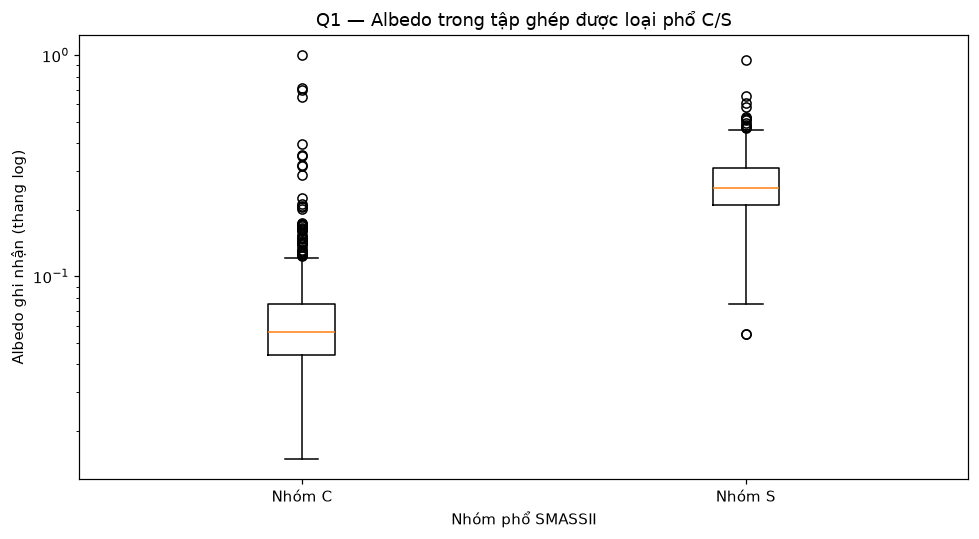

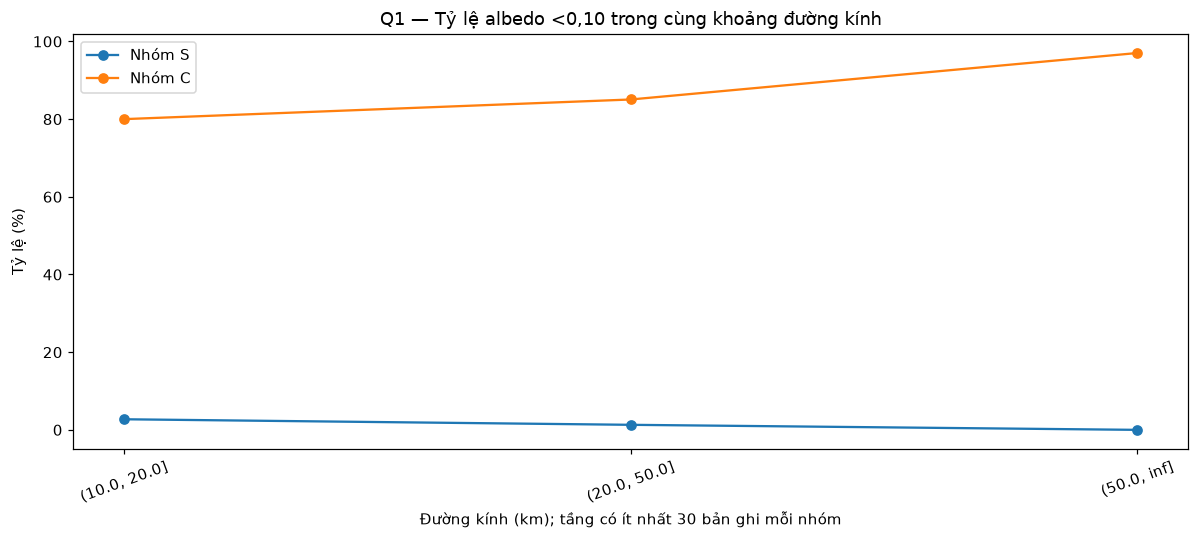

**Trả lời Q1:** Ghép được **1,659** đối tượng với nhãn phổ JPL. Tập C/S có đủ số đo gồm **926** đối tượng. Sau chuẩn hóa khoảng đường kính, tỷ lệ albedo <0,10 là **87.92% ở C** và **1.29% ở S**; chênh lệch C−S **+86.62 điểm phần trăm**.

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([q1.loc[q1.spectral_group.eq(g), "albedo"] for g in ["C", "S"]], tick_labels=["Nhóm C", "Nhóm S"])
ax.set(title="Q1 — Albedo trong tập ghép được loại phổ C/S", xlabel="Nhóm phổ SMASSII",
       ylabel="Albedo ghi nhận (thang log)")
ax.set_yscale("log"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
for group, column in [("S", "rate_reference"), ("C", "rate_target")]:
    ax.plot(np.arange(len(q1_detail)), q1_detail[column]*100, marker="o", label=f"Nhóm {group}")
ax.set_xticks(np.arange(len(q1_detail)), [str(x) for x in q1_detail.index], rotation=20)
ax.set(title="Q1 — Tỷ lệ albedo <0,10 trong cùng khoảng đường kính",
       xlabel="Đường kính (km); tầng có ít nhất 30 bản ghi mỗi nhóm", ylabel="Tỷ lệ (%)")
ax.legend(); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Trả lời Q1:** Ghép được **{int(joined['_merge'].eq('both').sum()):,}** đối tượng với nhãn phổ JPL. "
    f"Tập C/S có đủ số đo gồm **{len(q1):,}** đối tượng. Sau chuẩn hóa khoảng đường kính, "
    f"tỷ lệ albedo <0,10 là **{q1_adjusted['target_rate']:.2%} ở C** và "
    f"**{q1_adjusted['reference_rate']:.2%} ở S**; chênh lệch C−S "
    f"**{q1_adjusted['difference']*100:+.2f} điểm phần trăm**."
))

## Q1.4. Giới hạn và giá trị của phép ghép

Phép ghép bổ sung **thông tin phân loại mới**, không phải tách một bảng rồi
ghép lại để gán D1. Tuy vậy, tập có nhãn phổ rất nhỏ và có tính chọn lọc;
không đại diện cho toàn bộ danh mục. Ký hiệu không khớp được giữ trong file
audit, không ghép bằng suy đoán. Nhãn phổ ở bản JPL hiện tại không xác nhận
trạng thái nhãn tại thời điểm snapshot Kaggle. Chỉ kết luận về liên hệ giữa
nhãn phổ ghép được và albedo ghi nhận trong tập đủ điều kiện.

# Q2. Đối chiếu độ bao phủ nhiều loại số đo bằng reshape

**Câu hỏi cụ thể:** Trong từng khoảng độ sáng tuyệt đối H, nhóm NEO và không-NEO có tỷ lệ được ghi nhận đường kính, albedo và độ bất định đường kính khác nhau thế nào? Nhóm nào có tỷ lệ đủ cả H–đường kính–albedo cao hơn?

**Tiêu chí: D2 + D3 + D4.** D2 chuyển bảng có nhiều cột chỉ báo thành bảng dài
để đối chiếu rồi pivot thành ma trận biểu đồ; D3 tạo các cờ có thông tin và
đủ bộ; D4 so sánh cùng khoảng H và chuẩn hóa tỷ lệ đủ bộ.

## Q2.1. Vì sao đáng hỏi?

Một đối tượng có H chưa chắc có đường kính hoặc albedo; có đường kính chưa
chắc có độ bất định đường kính. Biết loại thông tin nào thường thiếu và ở nhóm
nào giúp chọn tập phân tích tiếp theo, tránh kết luận dựa trên một tập rất nhỏ
mà không báo rõ. Mục tiêu là độ bao phủ thông tin trong dataset, không phải
khả năng tồn tại vật lý của thuộc tính đó.

## Q2.2. Quy trình và định nghĩa

1. Giữ nhãn `neo` N/Y; không chuyển nhãn thiếu thành N.
2. Tạo cờ có diameter >0, có albedo >0, có `diameter_sigma >=0`, đều hữu hạn.
   Cờ sigma là có giá trị được báo cáo, không chứng nhận độ tin cậy tuyệt đối.
3. Tạo `complete_physical` khi H hữu hạn và có cả diameter/albedo hợp lệ.
4. Giữ H hữu hạn cho bảng phân tầng, chia H rộng 2 mag và tính mẫu số từng nhóm.
5. Dùng `groupby` tạo bảng tỷ lệ dạng rộng, `melt` chuyển sang dạng dài,
   rồi `pivot` để vẽ ma trận nhóm–loại thông tin. Tính tỷ lệ đủ bộ trước/sau chuẩn hóa H.

**Vì không dùng thời gian?** `epoch` là thời điểm tham chiếu quỹ đạo, không phải
ngày phát hiện. Dataset không phải chuỗi quan sát lặp cho cùng đối tượng.
Trong D2, thao tác reshape đã phù hợp với câu hỏi này; không cần gán xu hướng thời gian giả.

In [5]:
q2 = subset(df, df.neo.isin(["N", "Y"]), "Q2", "Nhãn NEO hợp lệ")
q2["Đường kính"] = (np.isfinite(q2.diameter) & q2.diameter.gt(0)).astype(int)
q2["Albedo"] = (np.isfinite(q2.albedo) & q2.albedo.gt(0)).astype(int)
q2["Độ bất định đường kính"] = (np.isfinite(q2.diameter_sigma) & q2.diameter_sigma.ge(0)).astype(int)
q2["Đủ H–đường kính–albedo"] = (np.isfinite(q2.H) & q2["Đường kính"].eq(1) & q2["Albedo"].eq(1)).astype(int)
MEASURES = ["Đường kính", "Albedo", "Độ bất định đường kính", "Đủ H–đường kính–albedo"]
q2_overall = q2.groupby("neo")[MEASURES].mean()
q2_counts = q2.groupby("neo").size()
display(q2_overall.mul(100).assign(**{"Số bản ghi": q2_counts}))
q2_h = subset(q2, np.isfinite(q2.H), "Q2", "H hữu hạn để phân tầng")
q2_h["H_bin"] = pd.cut(q2_h.H, H_EDGES)
q2_wide = q2_h.groupby(["H_bin", "neo"], observed=True)[MEASURES].mean().reset_index()
q2_group_n = q2_h.groupby(["H_bin", "neo"], observed=True).size().rename("n").reset_index()
q2_wide = q2_wide.merge(q2_group_n, on=["H_bin", "neo"], validate="one_to_one")
q2_long = q2_wide.melt(id_vars=["H_bin", "neo", "n"], value_vars=MEASURES,
                      var_name="Loại thông tin", value_name="Tỷ lệ có thông tin")
assert len(q2_long) == len(q2_wide)*len(MEASURES)
assert not q2_long.duplicated(["H_bin", "neo", "Loại thông tin"]).any()
q2_roundtrip = q2_long.pivot(index=["H_bin", "neo"], columns="Loại thông tin", values="Tỷ lệ có thông tin")
pd.testing.assert_frame_equal(
    q2_roundtrip.reindex(columns=MEASURES).rename_axis(columns=None).sort_index(),
    q2_wide.set_index(["H_bin", "neo"])[MEASURES].sort_index(),
)
print(f"D2: bảng rộng {len(q2_wide)} dòng → bảng dài {len(q2_long)} dòng "
      f"(mỗi nhóm có {len(MEASURES)} loại thông tin); pivot khôi phục đúng tỷ lệ.")
print("Đây là các dòng thống kê nhóm–loại thông tin, không phải thêm thiên thể.")
display(q2_long.head(12))
q2_adjusted, q2_detail = standardized_rates(q2_h, "neo", "Đủ H–đường kính–albedo", ["H_bin"], "N", "Y")
display(q2_detail.rename(columns=LABELS))

Q2 | Nhãn NEO hợp lệ: 958,524 → 958,520 dòng; không dùng 4 dòng.


,Đường kính,Albedo,Độ bất định đường kính,Đủ H–đường kính–albedo,Số bản ghi
neo,,,,,
N,14.467335,14.354148,14.463166,13.941376,935625
Y,3.708233,3.502948,3.319502,3.485477,22895


Q2 | H hữu hạn để phân tầng: 958,520 → 952,257 dòng; không dùng 6,263 dòng.
D2: bảng rộng 18 dòng → bảng dài 72 dòng (mỗi nhóm có 4 loại thông tin); pivot khôi phục đúng tỷ lệ.
Đây là các dòng thống kê nhóm–loại thông tin, không phải thêm thiên thể.


,H_bin,neo,n,Loại thông tin,Tỷ lệ có thông tin
0,"(-inf, 10.0]",N,4273,Đường kính,0.195413
1,"(-inf, 10.0]",Y,1,Đường kính,1.000000
2,"(10.0, 12.0]",N,2660,Đường kính,0.904887
3,"(10.0, 12.0]",Y,1,Đường kính,1.000000
4,"(12.0, 14.0]",N,27016,Đường kính,0.732085
5,"(12.0, 14.0]",Y,13,Đường kính,0.923077
6,"(14.0, 16.0]",N,203418,Đường kính,0.381623
7,"(14.0, 16.0]",Y,176,Đường kính,0.517045
8,"(16.0, 18.0]",N,539175,Đường kính,0.055783
9,"(16.0, 18.0]",Y,967,Đường kính,0.223371


,n nhóm tham chiếu,Tỷ lệ nhóm tham chiếu,n nhóm đích,Tỷ lệ nhóm đích,Trọng số
H_bin,,,,,
"(14.0, 16.0]",203418,0.380458,176,0.482955,0.223877
"(16.0, 18.0]",539175,0.054828,967,0.208893,0.593954
"(18.0, 20.0]",148199,0.003144,3386,0.081512,0.166687
"(20.0, 22.0]",4366,0.000000,4581,0.030998,0.009838
"(22.0, 24.0]",262,0.000000,4871,0.012113,0.005644


## Q2.3. Đọc `melt` và `pivot` qua ví dụ

Trước `melt`, một dòng có dạng `H=(14;16], NEO=Y, Đường kính=0,5, Albedo=0,4`.
Sau `melt`, thông tin đó thành hai dòng cùng H/NEO nhưng cột “Loại thông tin”
lần lượt là Đường kính và Albedo, cột “Tỷ lệ có thông tin” là 0,5 và 0,4.
Thực tế có bốn loại thông tin nên số dòng bảng dài gấp bốn bảng rộng.

`pivot` biến tên loại thông tin/nhóm thành cột của ma trận. Nhờ vậy ta có thể
đặt tất cả các tỷ lệ trên **cùng thang 0–100%** và phát hiện nhóm thiếu loại số
đo nào. Không cộng số dòng bảng dài để đếm thiên thể, cũng không lấy trung bình
các tỷ lệ nhóm không có trọng số để thay tỷ lệ toàn tập. Kiểm tra round-trip
bên trên xác nhận reshape không làm đổi tỷ lệ.

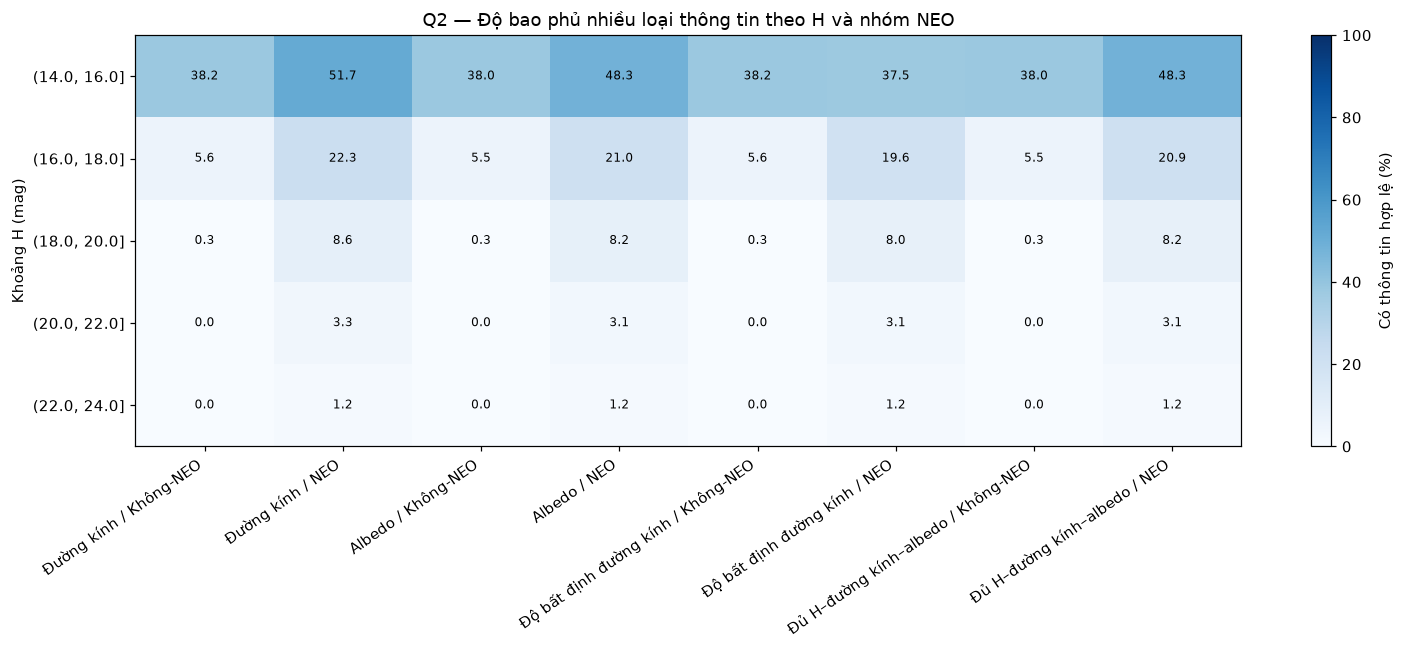

,Cách so sánh,Không-NEO (%),NEO (%)
0,Thô: toàn bộ nhãn NEO hợp lệ,13.941376,3.485477
1,Thô: chỉ vùng H chung,11.996605,5.464559
2,Chuẩn hóa: cùng vùng H chung,11.826535,24.615578


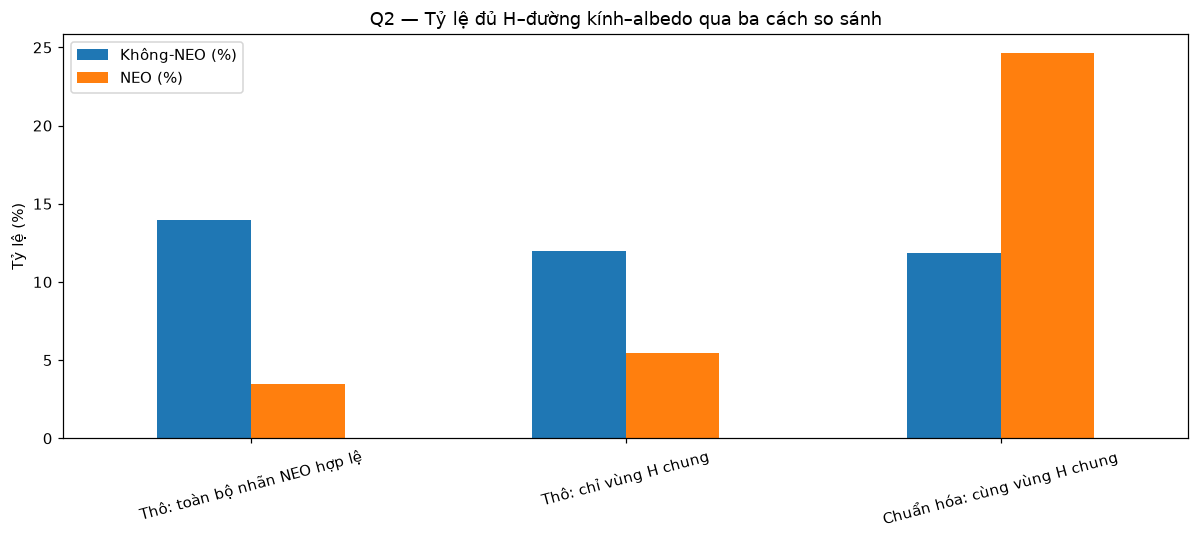

**Trả lời Q2:** Trước phân tầng, tỷ lệ đủ bộ là **13.94%** ở không-NEO và **3.49%** ở NEO. Trong vùng H chung sau chuẩn hóa, tỷ lệ là **11.83%** và **24.62%**, chênh lệch NEO−không-NEO **+12.79 điểm phần trăm**. Ma trận cho thấy loại thông tin và khoảng H cụ thể tạo nên các khác biệt.

In [6]:
common_h = q2_detail.index
heat_data = q2_long.loc[q2_long.H_bin.isin(common_h)].copy()
heat_data["Cột biểu đồ"] = heat_data["Loại thông tin"] + " / " + heat_data.neo.map(GROUP_LABELS)
heat = heat_data.pivot(index="H_bin", columns="Cột biểu đồ", values="Tỷ lệ có thông tin")
column_order = [f"{m} / {GROUP_LABELS[g]}" for m in MEASURES for g in ["N", "Y"]]
heat = heat.reindex(columns=column_order)
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(heat.to_numpy()*100, aspect="auto", vmin=0, vmax=100, cmap="Blues")
ax.set_xticks(np.arange(len(heat.columns)), heat.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(heat.index)), [str(x) for x in heat.index])
for row in range(len(heat.index)):
    for col in range(len(heat.columns)):
        value = heat.iloc[row, col]*100
        ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                color="white" if value > 55 else "black", fontsize=8)
ax.set(title="Q2 — Độ bao phủ nhiều loại thông tin theo H và nhóm NEO", ylabel="Khoảng H (mag)")
fig.colorbar(im, ax=ax, label="Có thông tin hợp lệ (%)")
plt.tight_layout(); plt.show()

q2_three_steps = pd.DataFrame([
    {"Cách so sánh": "Thô: toàn bộ nhãn NEO hợp lệ", "Không-NEO (%)": q2_overall.loc["N", MEASURES[-1]]*100,
     "NEO (%)": q2_overall.loc["Y", MEASURES[-1]]*100},
    {"Cách so sánh": "Thô: chỉ vùng H chung", "Không-NEO (%)": q2_adjusted["reference_common_rate"]*100,
     "NEO (%)": q2_adjusted["target_common_rate"]*100},
    {"Cách so sánh": "Chuẩn hóa: cùng vùng H chung", "Không-NEO (%)": q2_adjusted["reference_rate"]*100,
     "NEO (%)": q2_adjusted["target_rate"]*100},
])
display(q2_three_steps)
fig, ax = plt.subplots(figsize=(11, 5))
q2_three_steps.set_index("Cách so sánh").plot.bar(ax=ax)
ax.set(title="Q2 — Tỷ lệ đủ H–đường kính–albedo qua ba cách so sánh", ylabel="Tỷ lệ (%)", xlabel="")
ax.tick_params(axis="x", rotation=15); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Trả lời Q2:** Trước phân tầng, tỷ lệ đủ bộ là **{q2_overall.loc['N', MEASURES[-1]]:.2%}** "
    f"ở không-NEO và **{q2_overall.loc['Y', MEASURES[-1]]:.2%}** ở NEO. "
    f"Trong vùng H chung sau chuẩn hóa, tỷ lệ là **{q2_adjusted['reference_rate']:.2%}** và "
    f"**{q2_adjusted['target_rate']:.2%}**, chênh lệch NEO−không-NEO "
    f"**{q2_adjusted['difference']*100:+.2f} điểm phần trăm**. "
    "Ma trận cho thấy loại thông tin và khoảng H cụ thể tạo nên các khác biệt."
))

## Q2.4. Giới hạn

Nhãn “có thông tin” không chứng nhận số đo chính xác. Tập có H hữu hạn không
bao gồm mọi đối tượng; khoảng H không có đủ đối chứng được báo và không dùng
cho chuẩn hóa. H không phải độ sáng biểu kiến hoặc khoảng cách quan sát.
Khác biệt còn có thể liên quan đến chiến dịch quan sát và các yếu tố không có
trong dataset. Mục tiêu của reshape là đối chiếu nhiều loại thông tin bằng
một cấu trúc nhất quán, không tạo thêm dữ liệu hoặc xu hướng thời gian.

# Q3. Giả định albedo =0,15 làm đường kính tính từ H lệch bao nhiêu?

**Câu hỏi cụ thể:** Với các đối tượng có đủ H, albedo và đường kính, nếu tính đường kính từ H với albedo cố định 0,15, kết quả thường cao hay thấp hơn đường kính ghi nhận bao nhiêu phần trăm, và khác nhau thế nào giữa các nhóm albedo?

**Tiêu chí: D3 + D4.** D3 tạo đường kính ước lượng và mức lệch có dấu/tuyệt đối;
D4 xem quan hệ H–đường kính khi tách theo yếu tố thứ ba là albedo, và báo thêm
theo lớp quỹ đạo để thấy một con số tổng hợp có che mất các nhóm hay không.

## Q3.1. Vì sao đáng hỏi?

Q2 cho thấy thông tin kích thước có thể thiếu. Tuy vậy, cùng H không bảo đảm
cùng kích thước vì còn phụ thuộc albedo. Câu này lượng hóa hệ quả của một
giả định dễ áp dụng khi thiếu albedo. Đây là sử dụng công thức vật lý có sẵn,
không huấn luyện mô hình ML hoặc tuyên bố phát hiện quy luật mới.

[CNEOS/JPL](https://cneos.jpl.nasa.gov/tools/ast_size_est.html) cho công thức
`D (km) = 10 ** (3.1236 − 0.5 × log10(albedo) − 0.2 × H)`.

**Quy trình:** giữ H/diameter/albedo hữu hạn, diameter/albedo >0; tính đường
kính với albedo giả định 0,15; tính `100 × (D_tính/diameter −1)`; phân nhóm theo
albedo ghi nhận `(0;0,10]`, `(0,10;0,20]`, `>0,20`; so sánh trung vị mức lệch.
Các khoảng là quy ước của bài, không phải phân loại phổ chính thức.

In [7]:
q3 = subset(df, np.isfinite(df[["H", "diameter", "albedo"]]).all(axis=1)
    & df.diameter.gt(0) & df.albedo.gt(0), "Q3", "Có đủ H, đường kính và albedo hợp lệ")
q3["estimated_diameter"] = 10 ** (3.1236 - .5*np.log10(.15) - .2*q3.H)
q3["signed_error"] = 100*(q3.estimated_diameter/q3.diameter-1)
q3["absolute_error"] = q3.signed_error.abs()
q3["factor_two"] = (q3.estimated_diameter/q3.diameter > 2) | (q3.estimated_diameter/q3.diameter < .5)
q3["albedo_group"] = pd.cut(q3.albedo, [0, .1, .2, np.inf], labels=["(0;0,10]", "(0,10;0,20]", ">0,20"])
q3_groups = q3.groupby("albedo_group", observed=True).agg(n=("id", "size"),
    signed_median=("signed_error", "median"), MdAPE=("absolute_error", "median"),
    factor_two_rate=("factor_two", "mean"))
q3_classes = q3.groupby("class").agg(n=("id", "size"),
    signed_median=("signed_error", "median"), MdAPE=("absolute_error", "median"))
display(q3_groups.rename(columns={"n": "Số bản ghi", "signed_median": "Trung vị lệch có dấu (%)",
    "MdAPE": "Trung vị lệch tuyệt đối (%)", "factor_two_rate": "Tỷ lệ lệch hơn hệ số 2"}))
display(q3_classes.loc[q3_classes.n.ge(100)].rename(columns={"n": "Số bản ghi",
    "signed_median": "Trung vị lệch có dấu (%)", "MdAPE": "Trung vị lệch tuyệt đối (%)"}))
print("Bảng lớp quỹ đạo chỉ trình bày nhóm có ít nhất 100 bản ghi hợp lệ, không gộp các nhóm nhỏ.")

Q3 | Có đủ H, đường kính và albedo hợp lệ: 958,524 → 131,237 dòng; không dùng 827,287 dòng.


,Số bản ghi,Trung vị lệch có dấu (%),Trung vị lệch tuyệt đối (%),Tỷ lệ lệch hơn hệ số 2
albedo_group,,,,
"(0;0,10]",76796,-41.401949,41.407314,0.141010
"(0,10;0,20]",22890,-7.014943,11.776596,0.018174
">0,20",31551,27.635838,27.663845,0.006434


,Số bản ghi,Trung vị lệch có dấu (%),Trung vị lệch tuyệt đối (%)
class,,,
AMO,253,2.962905,41.735075
APO,454,-1.178558,34.784945
IMB,451,67.868166,67.868166
MBA,120420,-31.345809,36.131994
MCA,325,-4.332443,38.680520
OMB,7302,-40.606564,40.621868
TJN,1873,-35.000683,35.000683


Bảng lớp quỹ đạo chỉ trình bày nhóm có ít nhất 100 bản ghi hợp lệ, không gộp các nhóm nhỏ.


## Q3.2. Giải thích code và cách đọc phần trăm

Chia cho đường kính ghi nhận giúp đưa sai lệch của đối tượng nhỏ/lớn về cùng
thang tương đối. Ví dụ, ước tính 1 km khi nguồn ghi 2 km cho −50%; ước tính
4 km cho +100%. Hai trường hợp đều lệch hệ số 2. Vì thế cờ lệch hơn hệ số 2
dùng tỷ số `<0,5` hoặc `>2`, không dùng điều kiện phần trăm đối xứng ±100%.

**Trung vị lệch có dấu** cho biết xu hướng thấp/cao hơn; **MdAPE** lấy trị
tuyệt đối từng dòng rồi tính trung vị, giúp tránh lệch âm/dương triệt tiêu.
Không nhầm MdAPE với trị tuyệt đối của trung vị lệch có dấu.
Biểu đồ scatter chỉ lấy tối đa 8.000 điểm cho dễ nhìn; toàn bộ thống kê dùng
tất cả các bản ghi hợp lệ. Cột albedo chia nhóm giúp thấy H không phải yếu
tố duy nhất trong liên hệ giữa độ sáng và kích thước.

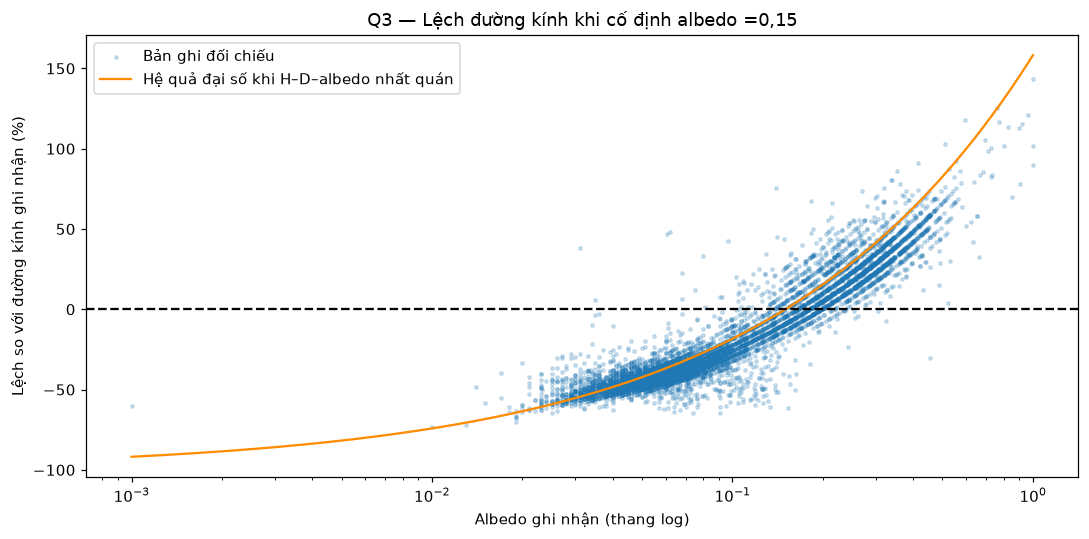

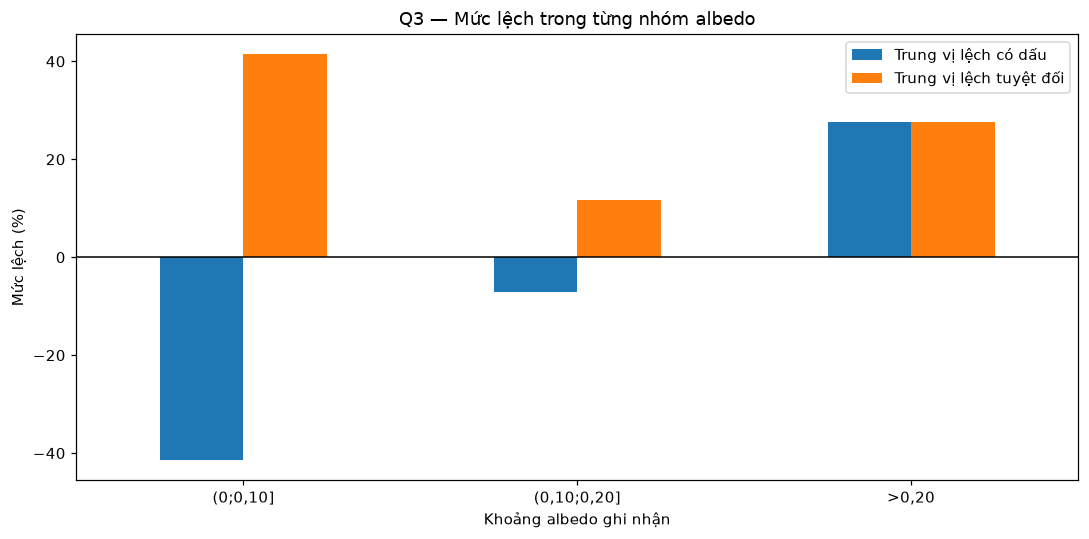

**Trả lời Q3:** Với **131,237** đối tượng hợp lệ, giả định albedo 0,15 cho trung vị lệch có dấu **-32.53%**, MdAPE **36.49%**; **8.72%** bản ghi lệch hơn hệ số 2. Cần đọc cùng bảng theo albedo để biết nhóm nào thường bị ước tính thấp/cao.

In [8]:
sample = q3.sample(n=min(8000, len(q3)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(sample.albedo, sample.signed_error, s=5, alpha=.2, label="Bản ghi đối chiếu")
grid = np.geomspace(q3.albedo.min(), q3.albedo.max(), 200)
ax.plot(grid, (np.sqrt(grid/.15)-1)*100, color="darkorange", label="Hệ quả đại số khi H–D–albedo nhất quán")
ax.axhline(0, color="black", linestyle="--"); ax.set_xscale("log")
ax.set(title="Q3 — Lệch đường kính khi cố định albedo =0,15", xlabel="Albedo ghi nhận (thang log)",
       ylabel="Lệch so với đường kính ghi nhận (%)")
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
q3_groups[["signed_median", "MdAPE"]].rename(columns={"signed_median": "Trung vị lệch có dấu", "MdAPE": "Trung vị lệch tuyệt đối"}).plot.bar(ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Q3 — Mức lệch trong từng nhóm albedo", xlabel="Khoảng albedo ghi nhận", ylabel="Mức lệch (%)")
ax.tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Trả lời Q3:** Với **{len(q3):,}** đối tượng hợp lệ, giả định albedo 0,15 "
    f"cho trung vị lệch có dấu **{q3.signed_error.median():+.2f}%**, "
    f"MdAPE **{q3.absolute_error.median():.2f}%**; **{q3.factor_two.mean():.2%}** bản ghi lệch hơn hệ số 2. "
    "Cần đọc cùng bảng theo albedo để biết nhóm nào thường bị ước tính thấp/cao."
))

## Q3.3. Giới hạn quan trọng

Albedo có thể được suy ra cùng H/diameter ở nguồn, nên ba trường không nhất
thiết độc lập. Mức khớp của công thức không phải kiểm chứng độc lập về khả năng
dự đoán; đồ thị là hệ quả một giả định đã biết. Đường kính ghi nhận là mốc đối
chiếu, không phải kích thước thật đã biết chính xác. Tập có đủ ba trường có
tính chọn lọc như Q2 mô tả; không dùng kết quả để cam kết mức chính xác cho
toàn bộ các đối tượng còn thiếu đường kính.

# Q4. So sánh albedo thấp giữa các lớp quỹ đạo khi xét kích thước

**Câu hỏi cụ thể:** So với MBA, OMB và TJN có tỷ lệ đối tượng có albedo dưới 0,10 chênh lệch bao nhiêu điểm phần trăm khi so sánh cùng khoảng đường kính?

**Tiêu chí: D3 + D4.** D3 tạo cờ `albedo <0,10` và các khoảng đường kính;
D4 so sánh trong khoảng và chuẩn hóa cơ cấu kích thước khi so sánh từng cặp.

## Q4.1. Lý do và quy trình

Q1 xem phân loại **phổ**, còn câu này xem phân loại **quỹ đạo**. Ta muốn biết
các nhóm theo quỹ đạo có khác mức phản chiếu trong tập được đo hay không,
đồng thời tránh nhầm khác biệt do cơ cấu kích thước thành khác biệt giữa lớp.
Người quan tâm là nhóm đang lựa chọn cách so sánh đặc điểm vật lý giữa các lớp.

1. Chọn MBA (vành đai chính), OMB (vành đai ngoài), TJN (Trojan Sao Mộc),
   là các nhóm có tương đối nhiều albedo trong bản dữ liệu này.
2. Giữ diameter và albedo hữu hạn, dương. Tạo `low_albedo = albedo <0,10`.
3. Tính tỷ lệ thô và mẫu số cho từng lớp, không so sánh số lượng tuyệt đối.
4. So sánh OMB−MBA và TJN−MBA trong các khoảng đường kính (0;2], (2;5],
   (5;10], (10;20], >20 km, giữ tầng có ≥30 bản ghi ở mỗi lớp.
5. Dùng cùng cơ cấu tầng trong từng cặp rồi báo chênh lệch tính bằng điểm %.

In [9]:
q4 = subset(df, df["class"].isin(["MBA", "OMB", "TJN"]), "Q4", "Ba lớp quỹ đạo cần so sánh")
q4 = subset(q4, np.isfinite(q4[["diameter", "albedo"]]).all(axis=1)
    & q4.diameter.gt(0) & q4.albedo.gt(0), "Q4", "Có đường kính và albedo hợp lệ")
q4["low_albedo"] = (q4.albedo < .1).astype(int)
q4["D_bin"] = pd.cut(q4.diameter, [0, 2, 5, 10, 20, np.inf])
q4_raw = q4.groupby("class").agg(n=("id", "size"),
    median_albedo=("albedo", "median"), low_albedo_rate=("low_albedo", "mean"))
display(q4_raw.rename(columns={"n": "Số bản ghi", "median_albedo": "Trung vị albedo", "low_albedo_rate": "Tỷ lệ albedo <0,10"}))
q4_results, q4_details, q4_rows = {}, {}, []
for target in ["OMB", "TJN"]:
    r, detail = standardized_rates(q4, "class", "low_albedo", ["D_bin"], "MBA", target)
    q4_results[target], q4_details[target] = r, detail
    print(f"Cặp {target}−MBA: {r['n_strata']} tầng; {r['n_reference']:,} MBA và {r['n_target']:,} {target} trong vùng chung.")
    display(detail.rename(columns=LABELS))
    for label, ref_rate, target_rate in [
        ("Thô: toàn tập hợp lệ", q4_raw.loc["MBA", "low_albedo_rate"], q4_raw.loc[target, "low_albedo_rate"]),
        ("Thô: chỉ vùng đường kính chung", r["reference_common_rate"], r["target_common_rate"]),
        ("Chuẩn hóa: cùng vùng đường kính chung", r["reference_rate"], r["target_rate"]),
    ]:
        q4_rows.append({"Cặp": f"{target}−MBA", "Cách so sánh": label, "MBA (%)": ref_rate*100,
                        "Nhóm đích (%)": target_rate*100, "Chênh lệch (điểm %)": (target_rate-ref_rate)*100})
q4_comparison = pd.DataFrame(q4_rows)
display(q4_comparison)

Q4 | Ba lớp quỹ đạo cần so sánh: 958,524 → 892,530 dòng; không dùng 65,994 dòng.
Q4 | Có đường kính và albedo hợp lệ: 892,530 → 133,320 dòng; không dùng 759,210 dòng.


,Số bản ghi,Trung vị albedo,"Tỷ lệ albedo <0,10"
class,,,
MBA,124001,0.081,0.571584
OMB,7446,0.060,0.890545
TJN,1873,0.070,0.846236


Cặp OMB−MBA: 5 tầng; 124,001 MBA và 7,446 OMB trong vùng chung.


,n nhóm tham chiếu,Tỷ lệ nhóm tham chiếu,n nhóm đích,Tỷ lệ nhóm đích,Trọng số
D_bin,,,,,
"(0.0, 2.0]",11559,0.348214,30,0.733333,0.088165
"(2.0, 5.0]",74038,0.535887,2088,0.827586,0.579138
"(5.0, 10.0]",31521,0.706672,3947,0.915885,0.269827
"(10.0, 20.0]",5155,0.718914,1034,0.919729,0.047084
"(20.0, inf]",1728,0.691551,347,0.907781,0.015786


Cặp TJN−MBA: 3 tầng; 38,404 MBA và 1,873 TJN trong vùng chung.


,n nhóm tham chiếu,Tỷ lệ nhóm tham chiếu,n nhóm đích,Tỷ lệ nhóm đích,Trọng số
D_bin,,,,,
"(5.0, 10.0]",31521,0.706672,101,0.851485,0.785113
"(10.0, 20.0]",5155,0.718914,1217,0.808546,0.158204
"(20.0, inf]",1728,0.691551,555,0.927928,0.056682


,Cặp,Cách so sánh,MBA (%),Nhóm đích (%),Chênh lệch (điểm %)
0,OMB−MBA,Thô: toàn tập hợp lệ,57.158410,89.054526,31.896116
1,OMB−MBA,Thô: chỉ vùng đường kính chung,57.158410,89.054526,31.896116
2,OMB−MBA,Chuẩn hóa: cùng vùng đường kính chung,57.649803,84.870635,27.220832
3,TJN−MBA,Thô: toàn tập hợp lệ,57.158410,84.623599,27.465188
4,TJN−MBA,Thô: chỉ vùng đường kính chung,70.763462,84.623599,13.860136
5,TJN−MBA,Chuẩn hóa: cùng vùng đường kính chung,70.775139,84.902489,14.127350


## Q4.2. Vì sao so sánh tỷ lệ và từng cặp?

MBA có nhiều bản ghi hơn hẳn, nên đếm số đối tượng albedo thấp không trả lời
được nhóm nào **có tỷ lệ** cao hơn. Một lớp tăng từ 40% lên 60% là tăng
20 **điểm phần trăm**, tương ứng tăng 50% tương đối; notebook dùng điểm phần
trăm để biểu thị hiệu hai tỷ lệ.

Mỗi cặp có vùng kích thước chung và trọng số riêng. Vì vậy không lấy hai tỷ
lệ đã chuẩn hóa của OMB/TJN ở hai cặp khác nhau để lập một bảng xếp hạng trên
cùng quần thể. Đọc cả bảng số mẫu và ba cách so sánh. Khác biệt từ toàn tập
sang vùng chung không thể chỉ quy cho chuẩn hóa trọng số.

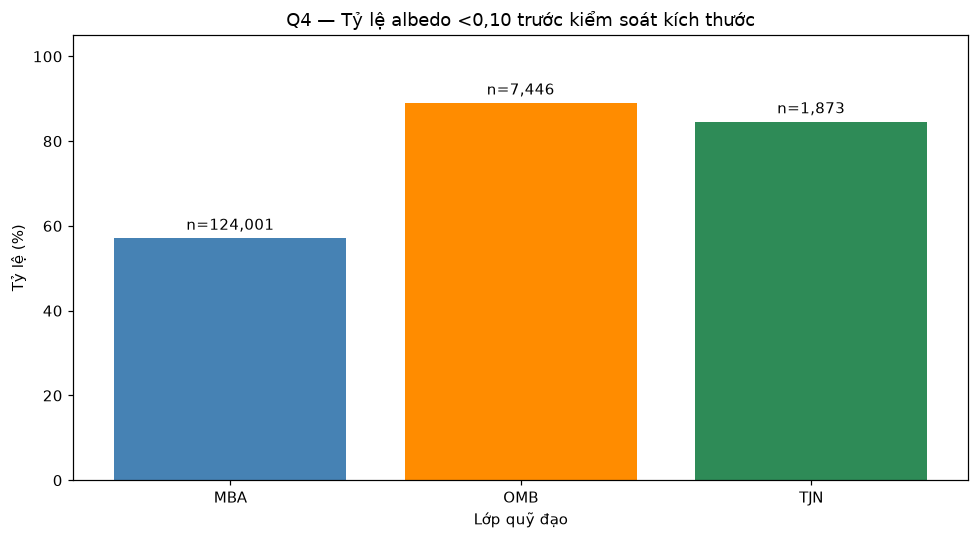

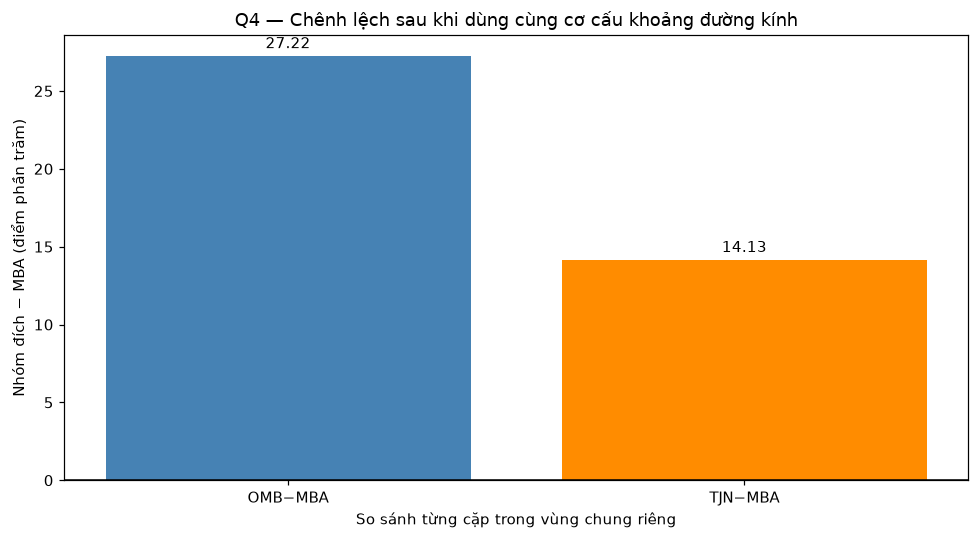

**Trả lời Q4 (OMB−MBA):** Sau chuẩn hóa, tỷ lệ albedo <0,10 là **84.87% ở OMB** và **57.65% ở MBA**; chênh lệch **+27.22 điểm phần trăm**. Phép tính dùng 7,446 OMB và 124,001 MBA trong vùng chung.

**Trả lời Q4 (TJN−MBA):** Sau chuẩn hóa, tỷ lệ albedo <0,10 là **84.90% ở TJN** và **70.78% ở MBA**; chênh lệch **+14.13 điểm phần trăm**. Phép tính dùng 1,873 TJN và 38,404 MBA trong vùng chung.

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
order = ["MBA", "OMB", "TJN"]
bars = ax.bar(order, q4_raw.loc[order, "low_albedo_rate"]*100, color=["steelblue", "darkorange", "seagreen"])
ax.bar_label(bars, labels=[f"n={q4_raw.loc[g,'n']:,}" for g in order], padding=3)
ax.set(title="Q4 — Tỷ lệ albedo <0,10 trước kiểm soát kích thước", xlabel="Lớp quỹ đạo", ylabel="Tỷ lệ (%)", ylim=(0, 105))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
adjusted_rows = q4_comparison.loc[q4_comparison["Cách so sánh"].str.startswith("Chuẩn hóa")]
bars = ax.bar(adjusted_rows["Cặp"], adjusted_rows["Chênh lệch (điểm %)"], color=["steelblue", "darkorange"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Q4 — Chênh lệch sau khi dùng cùng cơ cấu khoảng đường kính",
       xlabel="So sánh từng cặp trong vùng chung riêng", ylabel="Nhóm đích − MBA (điểm phần trăm)")
plt.tight_layout(); plt.show()
for target, r in q4_results.items():
    display(Markdown(
        f"**Trả lời Q4 ({target}−MBA):** Sau chuẩn hóa, tỷ lệ albedo <0,10 là "
        f"**{r['target_rate']:.2%} ở {target}** và **{r['reference_rate']:.2%} ở MBA**; "
        f"chênh lệch **{r['difference']*100:+.2f} điểm phần trăm**. "
        f"Phép tính dùng {r['n_target']:,} {target} và {r['n_reference']:,} MBA trong vùng chung."
    ))

## Q4.3. Giới hạn

Đây là sự khác biệt mô tả trong tập có số đo, không chứng minh lớp quỹ đạo
gây ra albedo thấp. Đường kính và albedo có thể được suy ra cùng nhau, nên
kiểm soát khoảng đường kính chưa tách được hoàn toàn quan hệ giữa hai đại
lượng. Nhóm thiếu số đo nhiều không được đại diện đầy đủ. Ngưỡng 0,10 chỉ là
quy ước; không dùng tỷ lệ này để khẳng định thành phần vật chất.

## B. Kiểm tra dữ liệu và xuất bảng kết quả

Các kiểm tra dưới đây bảo đảm phép ghép không làm nhân dòng, reshape không
đổi tỷ lệ, biến dẫn xuất có giá trị hợp lệ và các trọng số cộng thành 1.
Đây là kiểm tra tính đúng của code, **không tự gán thành tiêu chí D6**.
Không thay đổi file raw hoặc file dữ liệu chung của Notebook 01.

In [11]:
assert len(df) == input_rows and len(joined) == input_rows
assert q1.low_albedo.isin([0, 1]).all() and q4.low_albedo.isin([0, 1]).all()
assert q2[MEASURES].isin([0, 1]).all().all()
assert np.isfinite(q3.signed_error).all()
assert np.isclose(q1_detail.weight.sum(), 1) and np.isclose(q2_detail.weight.sum(), 1)
assert all(np.isclose(d.weight.sum(), 1) for d in q4_details.values())
assert sha256(DATA_PATH) == source_sha256
assert sha256(TAXONOMY_PATH) == taxonomy_metadata["sha256"]
print("Đã kiểm tra ghép 1–1, reshape, biến dẫn xuất, trọng số và bảo toàn nguồn.")
audit_table = pd.DataFrame(audit)
display(audit_table)
OUTPUT_DIR = PROJECT_ROOT / "data/processed/d1_d4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tables = {
    "row_counts.csv": audit_table, "q1_join_audit.csv": join_audit,
    "q1_unmatched_jpl.csv": unmatched_taxonomy, "q1_spectral_summary.csv": q1_raw.reset_index(),
    "q1_comparison.csv": q1_comparison, "q2_coverage_wide.csv": q2_wide,
    "q2_coverage_long.csv": q2_long, "q2_comparison.csv": q2_three_steps,
    "q3_errors_by_albedo.csv": q3_groups.reset_index(), "q3_errors_by_orbit.csv": q3_classes.reset_index(),
    "q4_comparison.csv": q4_comparison,
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR/name, index=False, encoding="utf-8-sig")
print(f"Đã lưu {len(tables)} bảng kết quả vào {OUTPUT_DIR.relative_to(PROJECT_ROOT)}.")

Đã kiểm tra ghép 1–1, reshape, biến dẫn xuất, trọng số và bảo toàn nguồn.


,Câu hỏi,Bước,Trước,Sau,Không dùng trong phân tích này
0,Q1,Nhãn phổ thuộc nhóm C/S đã chọn,958524,1123,957401
1,Q1,Có đường kính và albedo hợp lệ,1123,926,197
2,Q2,Nhãn NEO hợp lệ,958524,958520,4
3,Q2,H hữu hạn để phân tầng,958520,952257,6263
4,Q3,"Có đủ H, đường kính và albedo hợp lệ",958524,131237,827287
5,Q4,Ba lớp quỹ đạo cần so sánh,958524,892530,65994
6,Q4,Có đường kính và albedo hợp lệ,892530,133320,759210


Đã lưu 11 bảng kết quả vào data\processed\d1_d4.


## C. Tự kiểm tra hiểu bài và cách trình bày

- **Q1/D1:** Dữ liệu nào được bổ sung? Vì sao dùng `pdes` thay cho `spkid`?
  `left join` giữ dòng nào? `validate` và khóa không khớp giúp phát hiện vấn đề gì?
- **Q2/D2:** Một dòng bảng dài đại diện cho thiên thể hay một nhóm–loại thông
  tin? Vì sao `melt` làm tăng số dòng nhưng không tăng số thiên thể? `pivot`
  phục vụ câu hỏi và biểu đồ nào? Vì sao không dùng `epoch` làm năm phát hiện?
- **Q3/D3:** Công thức tạo biến mới có nguồn nào? Mức lệch âm nghĩa là gì?
  Vì sao trung vị lệch có dấu khác trung vị lệch tuyệt đối?
- **Q1/Q2/Q4/D4:** Biến thứ ba được kiểm soát là gì? Trọng số chung khác cơ
  cấu mẫu riêng của hai nhóm thế nào? Phép so sánh áp dụng cho vùng đối tượng nào?

Trình bày mỗi câu theo sáu ý: **hỏi gì → vì sao đáng hỏi → tập được dùng →
đại lượng/cách tính → kết quả bằng số → giới hạn**. Các câu là đề xuất chờ
nhóm trưởng duyệt; nhóm cần hiểu và tự kiểm tra trước khi dùng làm bài nộp.

### Tài liệu tham khảo

- [Dataset Kaggle](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset).
- [JPL SBDB Query: spec_B là phân loại phổ SMASSII, pdes là ký hiệu chính](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html).
- [JPL: phân loại quỹ đạo MBA/OMB/TJN](https://ssd-api.jpl.nasa.gov/doc/sbdb_filter.html).
- [Mainzer và cộng sự (2011): NEOWISE và các nhóm phổ, mô tả complex C/S và SMASSII không dùng albedo để phân lớp](https://doi.org/10.1088/0004-637x/741/2/90).
- [CNEOS: công thức ước lượng kích thước từ H và albedo](https://cneos.jpl.nasa.gov/tools/ast_size_est.html).
- [pandas: melt](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.melt.html),
  [pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html),
  [merge và validate](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html).

Đối chiếu tài liệu ngày 16/11/2026; ngày tải thực tế của bảng JPL được ghi
trong metadata. Có hỗ trợ AI trong đặt câu hỏi, code và giải thích; ghi nhận
trong `LLM_USAGE.md`. Notebook 01 được giữ nguyên; bảng phân tích cũ trong
`data/processed/q1_q4/` không phải đầu ra của phiên bản D1–D4 này.